# Tốc độ học và các vấn đề thường gặp của Gradient Descent

*Bài 5, mục 5.1.4.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def gd(grad, x0, eta, max_iter=100, tol=1e-3):
    x = x0
    lich_su = [x0]
    for _ in range(max_iter):
        x = x - eta * grad(x)
        lich_su.append(x)
        if abs(grad(x)) < tol or not np.isfinite(x):
            break
    return np.array(lich_su)

## 1. Ảnh hưởng của tốc độ học

$f(x) = x^2 + 5\sin x$, $x_0 = -5$: $\eta$ quá nhỏ hội tụ chậm, vừa phải hội tụ nhanh, quá lớn dao động.

eta = 0.01: 100 vòng lặp, x = -1.1180, f(x) = -3.2462
eta = 0.1 :  12 vòng lặp, x = -1.1106, f(x) = -3.2464
eta = 0.5 : 100 vòng lặp, x = -0.0631, f(x) = -0.3111


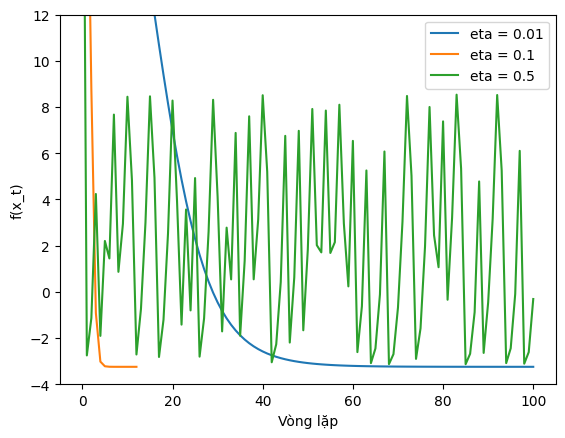

In [2]:
f = lambda x: x**2 + 5 * np.sin(x)
df = lambda x: 2 * x + 5 * np.cos(x)

for eta in [0.01, 0.1, 0.5]:
    h = gd(df, -5, eta)
    print('eta = %-4s: %3d vòng lặp, x = %7.4f, f(x) = %7.4f' % (eta, len(h) - 1, h[-1], f(h[-1])))
    plt.plot(f(h), label='eta = %s' % eta)
plt.xlabel('Vòng lặp'); plt.ylabel('f(x_t)'); plt.ylim(-4, 12)
plt.legend(); plt.show()

## 2. Phân tích với hàm bậc hai $f(x) = (x + 2)^2$

$x_{t+1} + 2 = (1 - 2\eta)(x_t + 2)$: khoảng cách tới cực tiểu nhân với $(1 - 2\eta)$ sau mỗi bước. GD hội tụ khi và chỉ khi $0 < \eta < 1$.

In [3]:
for eta in [0.25, 0.5, 0.75, 1.0, 1.1]:
    h = gd(lambda x: 2 * x + 4, 0.0, eta, max_iter=6, tol=0)
    print('eta = %-4s (hệ số %5.2f): x_t = %s' % (eta, 1 - 2 * eta, np.round(h, 3)))

eta = 0.25 (hệ số  0.50): x_t = [ 0.    -1.    -1.5   -1.75  -1.875 -1.938 -1.969]
eta = 0.5  (hệ số  0.00): x_t = [ 0. -2. -2. -2. -2. -2. -2.]
eta = 0.75 (hệ số -0.50): x_t = [ 0.    -3.    -1.5   -2.25  -1.875 -2.062 -1.969]
eta = 1.0  (hệ số -1.00): x_t = [ 0. -4.  0. -4.  0. -4.  0.]
eta = 1.1  (hệ số -1.20): x_t = [ 0.    -4.4    0.88  -5.456  2.147 -6.977  3.972]


## 3. Mắc kẹt tại cực tiểu địa phương

$f(x) = x^4 - 3x^2 + x$ có cực tiểu toàn cục tại $x \approx -1.30$ và cực tiểu địa phương tại $x \approx 1.13$. Kết quả phụ thuộc điểm khởi tạo.

x0 = -2.0 -> x = -1.3008, f(x) = -3.5139
x0 =  2.0 -> x =  1.1309, f(x) = -1.0702
Các điểm dừng (f'(x) = 0): [-1.3008  0.1699  1.1309]


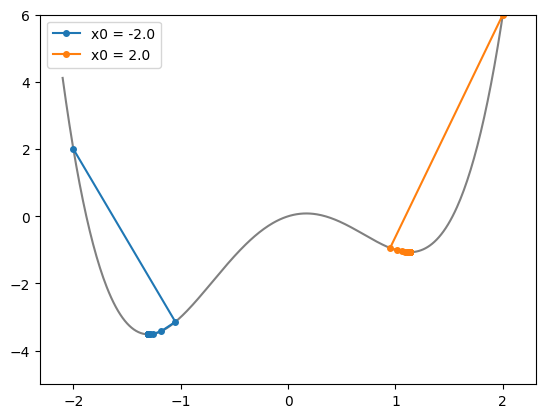

In [4]:
g = lambda x: x**4 - 3 * x**2 + x
dg = lambda x: 4 * x**3 - 6 * x + 1

xs = np.linspace(-2.1, 2.1, 400)
plt.plot(xs, g(xs), color='gray')
for x0 in [-2.0, 2.0]:
    h = gd(dg, x0, 0.05, max_iter=200, tol=1e-6)
    print('x0 = %4.1f -> x = %7.4f, f(x) = %7.4f' % (x0, h[-1], g(h[-1])))
    plt.plot(h, g(h), 'o-', ms=4, label='x0 = %.1f' % x0)
print("Các điểm dừng (f'(x) = 0):", np.sort(np.roots([4, 0, -6, 1])).round(4))
plt.ylim(-5, 6); plt.legend(); plt.show()